In [1]:
!pip install opencv-python matplotlib


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


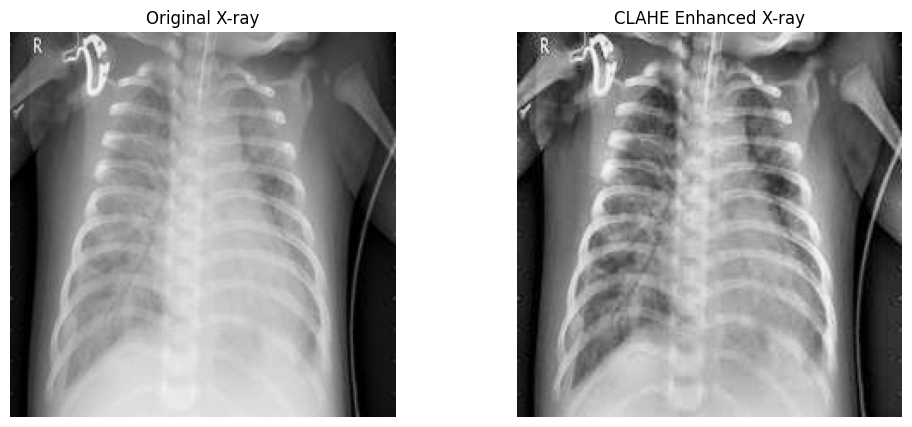

In [2]:
import cv2
import os
import matplotlib.pyplot as plt

# Select one chest X-ray image
image_path = r"C:\Users\HP\OneDrive\Desktop\MediMind\chest_xray_resized\train\PNEUMONIA"

filename = os.listdir(image_path)[0]

full_path = os.path.join(image_path, filename)

# Read image in grayscale
image = cv2.imread(full_path, cv2.IMREAD_GRAYSCALE)

# Create CLAHE object
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

# Apply CLAHE
enhanced_image = clahe.apply(image)

# Display comparison
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original X-ray")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(enhanced_image, cmap="gray")
plt.title("CLAHE Enhanced X-ray")
plt.axis("off")

plt.show()

In [3]:
import os
import cv2
from tqdm import tqdm

input_dir = r"C:\Users\HP\OneDrive\Desktop\MediMind\chest_xray_resized"

output_dir = r"C:\Users\HP\OneDrive\Desktop\MediMind\chest_xray_clahe"

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

for split in ["train", "test", "val"]:

    for category in ["NORMAL", "PNEUMONIA"]:

        src_folder = os.path.join(input_dir, split, category)
        dst_folder = os.path.join(output_dir, split, category)

        os.makedirs(dst_folder, exist_ok=True)

        files = [
            f for f in os.listdir(src_folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        for filename in tqdm(files, desc=f"{split}/{category}"):

            src_path = os.path.join(src_folder, filename)
            dst_path = os.path.join(dst_folder, filename)

            image = cv2.imread(src_path, cv2.IMREAD_GRAYSCALE)

            if image is None:
                print("Could not read:", filename)
                continue

            enhanced = clahe.apply(image)

            cv2.imwrite(dst_path, enhanced)

print("CLAHE preprocessing completed!")

val/PNEUMONIA: 100%|█████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 52.76it/s]

CLAHE preprocessing completed!


In [4]:
for split in ["train", "test", "val"]:
    for category in ["NORMAL", "PNEUMONIA"]:

        folder = os.path.join(output_dir, split, category)

        print(split, category, ":", len(os.listdir(folder)))

train NORMAL : 1341
train PNEUMONIA : 3875
test NORMAL : 234
test PNEUMONIA : 390
val NORMAL : 8
val PNEUMONIA : 8
